# **[실습 3] KNN**

## **[실습 3-1] KNN Classifier**

### **데이터셋 설명**

400명의 인물의 나이와 연봉 정보를 토대로 특정 물품을 구매할지에 대한 결과를 가진 데이터입니다.


| 컬럼명 | 설명 |
|---|---|
| User ID| 고객 ID|
| Gender | 고객의 성별 (Male, Female) |
| Age | 고객의 나이 |
| EstimatedSalary | 고객의 추측 연봉 |
| Purchased | **[target]** 상품을 구매=1, 상품을 구매하지 않음=0|

### **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/purchased.csv

### **[1-1]. 데이터 확인하기**

#### **1. 데이터 불러오기**

**Q1. 데이터를 불러오고, 데이터의 상위 5행만 출력해보자.**

In [110]:
import pandas as  pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/purchased.csv")
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


#### **2. 데이터 확인하기**

**Q1. 데이터의 결측치를 확인해보자**

In [111]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

**Q2. 데이터의 전반적인 정보를 확인해보자**

In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


**Q3. 데이터의 통계 요약을 확인해보자**

In [113]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


#### **3. 데이터 시각화하기**

**Q1. 남녀 성별의 비율을 파이 그래프로  그려보자.**

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

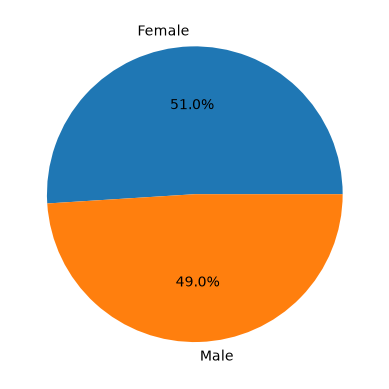

In [114]:
import matplotlib.pyplot as plt

temp = df['Gender'].value_counts()

plt.pie(temp, labels=temp.index, autopct='%.1f%%')
plt.show()

**Q2. 구매를 한 사람과 구매를 하지 않은 사람들의 비율을 막대그래프로 그려보자.**

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

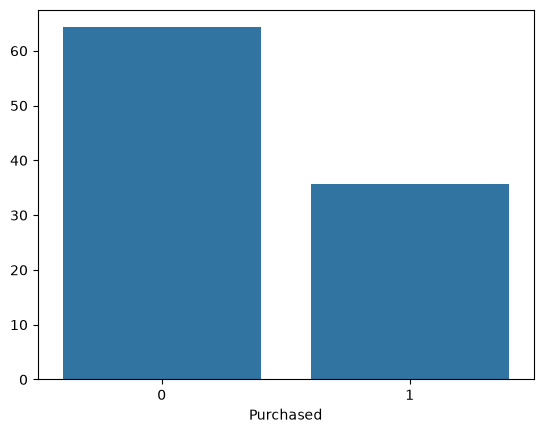

In [115]:
import seaborn as sns
ratio = df['Purchased'].value_counts(normalize=True).mul(100)
sns.barplot(x=ratio.index, y=ratio.values)
plt.show()

**Q3. 구매를 한 사람과 구매를 하지 않은 사람들을 성별로 나눠 막대그래프로 그려보자.**

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

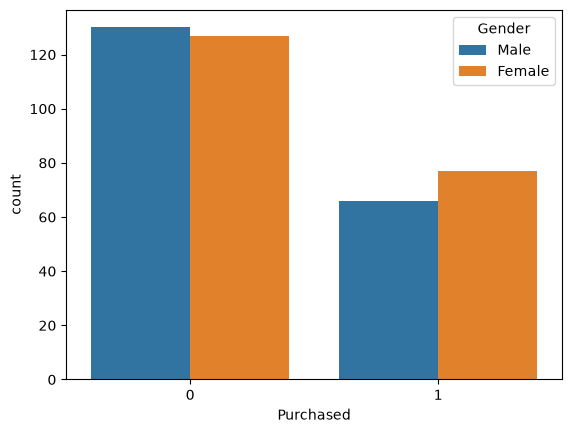

In [116]:
sns.countplot(data=df, x='Purchased', hue='Gender')
plt.show()

**Q4. 사람들의 연봉 분포도를 historgram으로 그려보자.**
- kde선을 같이 그려주도록 한다.

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

<Axes: xlabel='EstimatedSalary', ylabel='Count'>

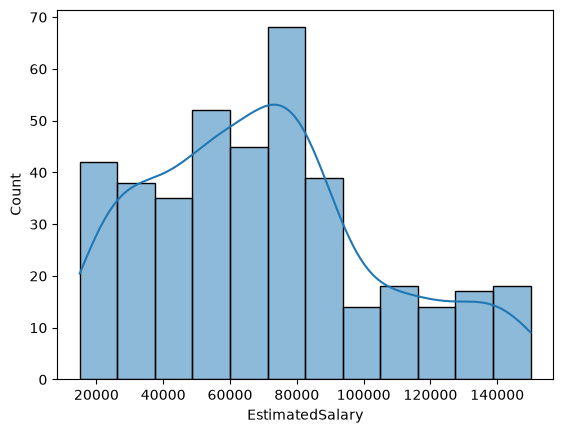

In [117]:
sns.histplot(df['EstimatedSalary'], kde=True)

**Q5. pairplot을 그려보도록 하자.**
- User ID 컬럼은 드랍시킨다.
- hue = 구매여부로 지정한다.

그리고 그래프로 알 수 있게된 정보를 코드 아래에 적어보자.

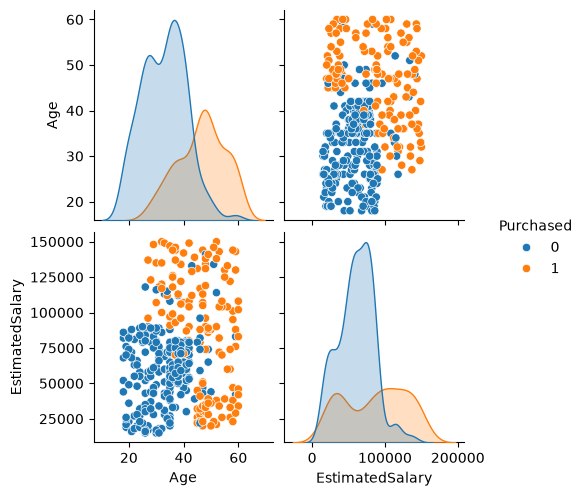

In [118]:
sns.pairplot(data=df.drop(columns='User ID'), hue='Purchased')
plt.show()

### **[1-2] 데이터 전처리**

In [119]:
# 전처리 과정에서 데이터가 망가지면 여기서부터 다시 실행합니다!
import pandas as  pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/purchased.csv")

#### **1. 데이터 삭제하기**

User ID행은 필요가 없으므로 드랍(삭제)한다.

In [120]:
df = df.drop('User ID', axis=1)
df

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0
...,...,...,...,...
395,Female,46,41000,1
396,Male,51,23000,1
397,Female,50,20000,1
398,Male,36,33000,0


#### **2. 학습 데이터와 테스트 데이터로 분리하기**

- Purchased를 제외한 모든 컬럼은 X 데이터,
- Purchased 컬럼이 y로서 라벨이 된다.
- 테스트 데이터의 비중은 30%
- 재현성을 위해 random_state는 101로 설정한다.

In [121]:
X = df.drop("Purchased", axis=1)    # Purchased 열만 drop한 나머지 열들 : Input
y = df["Purchased"]                 # Target

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
X_train.head()

,Gender,Age,EstimatedSalary
237,Female,37,80000
268,Female,47,144000
186,Female,20,82000
106,Female,26,35000
41,Female,33,51000


#### **3. 카테고리 변수 인코딩하기**

Gender의 경우 binary (0 또는 1) 인 경우일 것이다.
- Label Encoder를 사용하거나, map()을 활용하여 데이터를 변환해보자.

In [122]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

X_train["Gender"] = le.fit_transform(X_train["Gender"])
X_test["Gender"] = le.transform(X_test["Gender"])

X_train.head()

,Gender,Age,EstimatedSalary
237,0,37,80000
268,0,47,144000
186,0,20,82000
106,0,26,35000
41,0,33,51000


### **[1-3] 모델링**

#### **1. 모델 구현하기**

**Q1. KNNClassifier class를 생성한다.**
- KNN 프로세스를 따라 K-최근접 이웃의 결과를 예측한다.

In [123]:
class KNNClassifier():
    
    def __init__(self, k):
        self.k = k      # 총 몇개의 이웃을 확인해?
        self.X = None
        self.y = None   # 학습 데이터/라벨은 추후 새로운 정보가 들어왔을 때, 그냥 활용만 한다
        self.neighbors = []     # k개의 최근접 이웃들의 정보를 담아둠

    def fit(self, X, y):
        # lazy learning 모델로서, 실제로 학습하는건 없음
        self.X = X
        self.y = y 


    def predict(self, X):
        # X = 여러 새로운 데이터가 들어올 수 있습니다. numpy array
        self.neighbors = []
        predictions = []    # i번째 데이터에 대한 분류(예측값)을 순서대로 저장하여 return
        for x in X:
            y_pred = self.predict_one(x)    # 한 정보에 대한 예측값 구하고
            predictions.append(y_pred)
        return np.array(predictions)        # numpy array로 바꿔서 return

    def get_euclidean_dist(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    def predict_one(self, x):
        #1. x라는 새로운 데이터로부터 다른 모든 데이터(self.x)까지의 거리를 모두 구합니다.
        dists = [self.get_euclidean_dist(x, data) for data in self.X]
        #2. 정렬 -> 거리기반으로 정렬을 할건데... 사실 우리가 원하는거(나중에 쓸것) = 거리는 아님
        #3. 거기서 맨 앞의 self.k만큼만 잘라서 -> 이 정보들을 self.neighbors에 저장
        indexes = np.argsort(dists)[:self.k]
        # 이정보들은 우선 self.neighbors에 저장
        self.neighbors.append(indexes)  
        #4. 이 맨 앞의 self.k개의 정보들을 기반으로 y에 접근해서 각 라벨을 찾아서 -> 투표를 하게 할겁니다.
        labels = [self.y.iloc[i] for i in indexes]
        y_pred = np.argmax(np.bincount(labels))
        return y_pred


#### **2. 모델 생성, 학습하기**

**Q1. KNN 모델을 생성한다.**
- 확인할 K-최근접 이웃의 개수 (K value)는 5로 설정한다.

In [124]:
import numpy as np

# model = KNNClassifier(5)
# model.fit(X_train.values, y_train)

# new_data = np.array([[0, 40, 80000], [1, 50, 700000000]])

# y_pred = model.predict(new_data)
# print(y_pred)

In [125]:
model = KNNClassifier(5)

**Q2. 모델을 학습 데이터로 학습시킨다.**

In [126]:
model.fit(X_train.values, y_train)

#### **3. 모델 예측하기**

**Q1. 테스트 데이터(X_test)의 예측 결과를 y_pred에 저장한다.**

In [127]:
y_pred = model.predict(X_test.values)

#### **4. 모델 평가하기**

**Q1. 혼동 행렬을 그려 모델을 평가한다.**

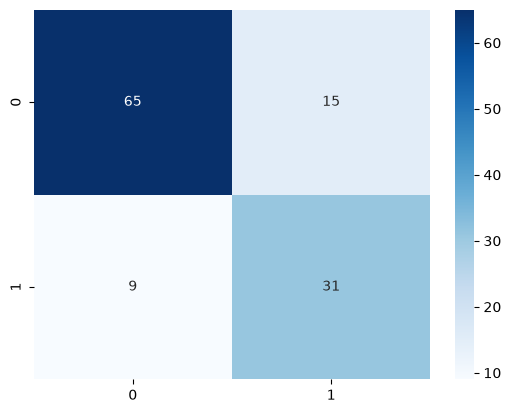

In [128]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='Blues')
plt.show()

**Q2. 정확도를 출력하여 모델을 평가한다.**

In [129]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test, y_pred))

0.8


### **[1-4] 결과 이해하기**

**Q1. 새로운 데이터의 예측 결과를 내보자.**

약 45살에 30000달러정도의 연봉이면, 구매를 했다 (Purchased=1) 이라는 결과가 나올것으로 예상할 수 있다.

In [130]:
new_data = np.array([[1, 45, 30000]])
pred = model.predict(new_data)
print(pred)

[1]


**Q2. 가까운 이웃 출력하기**
- knn.neighbors에는 참고한 k=5개의 이웃의 index가 기록되어있다.

In [131]:
model.neighbors # iloc index

[array([176,  64,  28, 187, 207])]

**Q3. 가까운 이웃 를 하나씩 확인해보자.**

In [132]:
X_train.iloc[model.neighbors[0]]
y_train.iloc[model.neighbors[0]]

27     1
323    1
158    0
131    0
365    1
Name: Purchased, dtype: int64

**Q4. 가까운 이웃들을 산점도 그래프에 어딨는지 표기해보자.**

그리고 이상한 점을 확인해보자.

In [133]:
X_train.iloc[model.neighbors[0]]["Age"]

27     47
323    48
158    26
131    33
365    59
Name: Age, dtype: int64

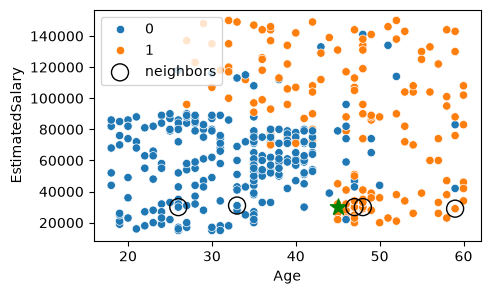

In [134]:
# code here
plt.figure(figsize=(5,3))
sns.scatterplot(df, x="Age", y="EstimatedSalary", hue="Purchased")
# 우리의 새로운 45살 아저씨 -> 이사람 어딨는지 한번 표기를 해볼게요 
plt.scatter(45, 30000, marker='*', color='green', s=150)
# 우리의 neighbor들에 대해서 어딨는 애들인지 한번 표기를 해봅시다. 
plt.scatter(
    x = X_train.iloc[model.neighbors[0]]["Age"],
    y = X_train.iloc[model.neighbors[0]]["EstimatedSalary"],
    label="neighbors",
    edgecolor='black',
    facecolor="none",
    s=150
)
plt.legend()
plt.show()
# 어 가장 가까운 5개를 취해야 하는데, 왜 이상한데 있는 애들이 잡혀올까? 

## **[실습 3-2] Feature Scaling**

### **[2-1] Feature Scaling 해보기**

#### **1. Normalization**

**Q1 정규화를 해보자.**
- 학습 데이터를 X_train_copy에 복사해둔다.
- 테스트 데이터를 X_test_copy에 복사해둔다.
- 그리고 sklearn의 MinMaxScaler를 활용하여 정규화를 해보자.

```
from sklearn.preprocesing import MinMaxScaler
scaler = MinMaxScaler()
```

테스트 데이터는 반드시 학습 데이터를 학습시킨 Scaler를 활용하여 data leakage를 방지한다.

In [135]:
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()

# 정규화
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

X_train_copy = scaler.fit_transform(X_train_copy)
X_train_copy

array([[0.        , 0.45238095, 0.48148148],
       [0.        , 0.69047619, 0.95555556],
       [0.        , 0.04761905, 0.4962963 ],
       [0.        , 0.19047619, 0.14814815],
       [0.        , 0.35714286, 0.26666667],
       [0.        , 0.21428571, 0.9037037 ],
       [1.        , 0.64285714, 0.47407407],
       [0.        , 0.07142857, 0.00740741],
       [1.        , 0.42857143, 0.95555556],
       [0.        , 0.66666667, 0.6       ],
       [1.        , 0.16666667, 0.48148148],
       [1.        , 0.19047619, 0.48148148],
       [0.        , 0.64285714, 0.85925926],
       [1.        , 0.0952381 , 0.48888889],
       [1.        , 0.54761905, 0.27407407],
       [0.        , 0.57142857, 0.28148148],
       [0.        , 0.23809524, 0.53333333],
       [0.        , 0.54761905, 0.26666667],
       [1.        , 0.5       , 0.2       ],
       [0.        , 0.57142857, 0.68888889],
       [1.        , 0.21428571, 0.03703704],
       [1.        , 0.54761905, 0.47407407],
       [0.

In [136]:
# code here

#### **2. Standardization**

**Q1 표준화를 해보자.**
- 학습 데이터를 X_train_copy에 복사해둔다.
- 테스트 데이터를 X_test_copy에 복사해둔다.
- 그리고 sklearn의 MinMaxScaler를 활용하여 정규화를 해보자.

```
from sklearn.preprocesing import StandardScaler
scaler = StandardScaler()
```

테스트 데이터는 반드시 학습 데이터를 학습시킨 Scaler를 활용하여 data leakage를 방지한다.

In [137]:
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()

# 정규화
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_copy = scaler.fit_transform(X_train_copy)
X_train_copy

array([[-0.96490128, -0.07024299,  0.30553739],
       [-0.96490128,  0.88917351,  2.20864132],
       [-0.96490128, -1.70125106,  0.36500939],
       [-0.96490128, -1.12560115, -1.03258256],
       [-0.96490128, -0.4540096 , -0.55680658],
       [-0.96490128, -1.0296595 ,  2.00048933],
       [ 1.03637545,  0.69729021,  0.27580139],
       [-0.96490128, -1.60530941, -1.59756654],
       [ 1.03637545, -0.16618465,  2.20864132],
       [-0.96490128,  0.79323186,  0.78131337],
       [ 1.03637545, -1.2215428 ,  0.30553739],
       [ 1.03637545, -1.12560115,  0.30553739],
       [-0.96490128,  0.69729021,  1.82207333],
       [ 1.03637545, -1.50936776,  0.33527339],
       [ 1.03637545,  0.31352361, -0.52707058],
       [-0.96490128,  0.40946526, -0.49733458],
       [-0.96490128, -0.93371785,  0.51368938],
       [-0.96490128,  0.31352361, -0.55680658],
       [ 1.03637545,  0.12164031, -0.82443057],
       [-0.96490128,  0.40946526,  1.13814536],
       [ 1.03637545, -1.0296595 , -1.478

In [138]:
# code here

### **[2-2] 데이터 스케일링**

**Q1. 학습 데이터를 기반으로 표준화를 진행한다.**
- 그리고 같은 scaler를 가지고 테스트 데이터를 표준화한다.
- X_train은 X_train_scaled에, X_test는 X_test_scaled에 저장한다
- 원본 데이터 (X_train, y_train)는 최종적으로 시각화를 할때 사용할 것이므로, 손상되게 해서는 안된다.

In [139]:
from sklearn.preprocessing import StandardScaler
model = StandardScaler()

X_train = model.fit_transform(X_train)
X_test = model.transform(X_test)

### **[2-3]. 모델링**

**Q1. KNN 분류기를 생성하고, scaling된 데이터를 기반으로 학습하도록 한다.**

In [140]:
model.fit(X_train, y_train)

StandardScaler()

### **[2-4]. 모델 예측, 평가하기**

**Q1. 테스트 데이터로 나온 예측 결과를 y_pred로 저장한다.**

In [141]:
y_pred = model.predict(X_test)

AttributeError: 'StandardScaler' object has no attribute 'predict'

**Q2. 혼동 행렬과 정확도, 그리고 분류 리포트를 확인한다.**

In [ ]:
plt.figure(figsize=(5,3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='Blues')
plt.show()

### **[2-5]. 결과 이해하기**

**Q1. 새로운 데이터의 예측 결과를 내보자.**

다시 45살에 30000달러정도의 연봉인 사람의 결과를 예측해보자.

그리고 이번에도 나온 이웃들을 산점도 그래프에 표시해보자.

In [ ]:
# code here

## **[실습 3-3] 최적의 K값 찾기**

### **[3-1]. Elbow Method**

**Q1. Elbow Method를 활용해서 최적의 K값 (Optimal K-value)를 찾아보자.**

In [ ]:
# code here

### **[3-2]. 모델링**

**Q1. 새로 찾은 최적의 K값으로 변경해서 학습시켜보자.**

- 다른 값으로 바꿔서 성능이 어떻게 바뀌는지 확인해보자.

In [ ]:
# code here

### **[3-3] 모델 평가**

**Q1. 정확도, 혼동행렬, 분류 리포트등을 통해 위에서 정한 K-최근접 이웃의 성능을 확인하자.**

In [ ]:
# code here